# Sales Agent Performance & Pipeline Analytics

**Dataset:** CRM Sales Opportunities (B2B sales pipeline of a fictitious computer-hardware company, via Maven Analytics, public domain). Four tables: `sales_pipeline` (8,800 opportunities), `accounts`, `products`, `sales_teams`.

**Business question:** Which sales agents convert opportunities into revenue effectively, which don't, and where should management act first?

**Approach:** Clean data, aggregate with SQL, engineer KPIs (win rate, conversion rate, revenue per opportunity), build a weighted performance score, classify agents as Good / Average / Poor, visualise, size the improvement opportunity, and test how robust the ranking is.

**Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn, SQL (SQLite)

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 200

DATA = Path("../data")
IMG = Path("../images")
OUT = Path("../outputs")
IMG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

## 2. Load and inspect the raw data

In [2]:
accounts = pd.read_csv(DATA / "accounts.csv")
products = pd.read_csv(DATA / "products.csv")
teams = pd.read_csv(DATA / "sales_teams.csv")
pipeline = pd.read_csv(DATA / "sales_pipeline.csv", parse_dates=["engage_date", "close_date"])

pd.DataFrame(
    {name: {"rows": len(df), "columns": df.shape[1], "null cells": int(df.isna().sum().sum()),
            "duplicate rows": int(df.duplicated().sum())}
     for name, df in [("accounts", accounts), ("products", products),
                      ("sales_teams", teams), ("sales_pipeline", pipeline)]}
).T

,rows,columns,null cells,duplicate rows
accounts,85,7,70,0
products,7,3,0,0
sales_teams,35,3,0,0
sales_pipeline,8800,8,6103,0


In [3]:
pipeline["deal_stage"].value_counts().to_frame("opportunities").assign(
    share_pct=lambda d: 100 * d["opportunities"] / d["opportunities"].sum()
)

,opportunities,share_pct
deal_stage,,
Won,4238,48.16
Lost,2473,28.10
Engaging,1589,18.06
Prospecting,500,5.68


### Where are the nulls?
The pipeline has many missing values, but they are **structural, not errors**. They depend on the deal stage:

In [4]:
pipeline.groupby("deal_stage").agg(
    opportunities=("opportunity_id", "count"),
    missing_account=("account", lambda s: s.isna().sum()),
    missing_engage_date=("engage_date", lambda s: s.isna().sum()),
    missing_close_date=("close_date", lambda s: s.isna().sum()),
    missing_close_value=("close_value", lambda s: s.isna().sum()),
    lost_with_zero_value=("close_value", lambda s: (s == 0).sum()),
)

,opportunities,missing_account,missing_engage_date,missing_close_date,missing_close_value,lost_with_zero_value
deal_stage,,,,,,
Engaging,1589,1088,0,1589,1589,0
Lost,2473,0,0,0,0,2473
Prospecting,500,337,500,500,500,0
Won,4238,0,0,0,0,0


Reading the table: Prospecting deals have no engage date yet; Prospecting and Engaging deals have no close date or value because they are still open; Lost deals have a close date and a value of 0; accounts are only missing on early-stage deals. None of this should be "fixed" by imputing values, because that would invent revenue.

## 3. Data cleaning

| Issue | Where | Fix |
|---|---|---|
| Product spelled `GTXPro` instead of `GTX Pro` | `sales_pipeline` | Standardise to match the `products` table |
| Sector typo `technolgy` | `accounts` | Correct to `technology` |
| Country typo `Philipines` | `accounts` | Correct to `Philippines` |
| Missing account on open early-stage deals | `sales_pipeline` | Label `Unassigned` (kept, not dropped) |
| Agents in `sales_teams` with no pipeline activity | `sales_teams` | Excluded from performance ranking |

In [5]:
n_gtx = (pipeline["product"] == "GTXPro").sum()
pipeline["product"] = pipeline["product"].replace({"GTXPro": "GTX Pro"})
accounts["sector"] = accounts["sector"].replace({"technolgy": "technology"})
accounts["office_location"] = accounts["office_location"].replace({"Philipines": "Philippines"})
pipeline["account"] = pipeline["account"].fillna("Unassigned")
print(f"Standardised {n_gtx} 'GTXPro' rows; fixed sector and country typos")

idle_agents = sorted(set(teams["sales_agent"]) - set(pipeline["sales_agent"]))
print(f"{len(idle_agents)} agents in sales_teams have no opportunities and are excluded: {idle_agents}")

Standardised 1480 'GTXPro' rows; fixed sector and country typos
5 agents in sales_teams have no opportunities and are excluded: ['Carl Lin', 'Carol Thompson', 'Elizabeth Anderson', 'Mei-Mei Johns', 'Natalya Ivanova']


### Integrity checks

In [6]:
closed = pipeline[pipeline["deal_stage"].isin(["Won", "Lost"])]
open_deals = pipeline[pipeline["deal_stage"].isin(["Prospecting", "Engaging"])]

assert pipeline["product"].isin(products["product"]).all(), "unknown product"
assert pipeline["sales_agent"].isin(teams["sales_agent"]).all(), "unknown agent"
assert pipeline.loc[pipeline["account"] != "Unassigned", "account"].isin(accounts["account"]).all(), "unknown account"
assert (closed["close_date"] >= closed["engage_date"]).all(), "deal closed before it was engaged"
assert (pipeline.loc[pipeline["deal_stage"] == "Lost", "close_value"] == 0).all(), "lost deal with revenue"
assert (pipeline.loc[pipeline["deal_stage"] == "Won", "close_value"] > 0).all(), "won deal without revenue"
assert open_deals["close_value"].isna().all(), "open deal with revenue"
print("All integrity checks passed")

All integrity checks passed


## 4. Aggregate per agent with SQL

The cleaned tables go into an in-memory SQLite database. Conditional aggregation (`CASE WHEN`) counts each deal stage in a single pass, and the result is joined to the team table for manager and regional office.

In [7]:
con = sqlite3.connect(":memory:")
pipeline.to_sql("pipeline", con, index=False)
teams.to_sql("teams", con, index=False)
accounts.to_sql("accounts", con, index=False)
products.to_sql("products", con, index=False)

query = """
WITH p AS (
    SELECT sales_agent,
           COUNT(*)                                                             AS opportunities,
           SUM(CASE WHEN deal_stage = 'Won'  THEN 1 ELSE 0 END)                 AS won,
           SUM(CASE WHEN deal_stage = 'Lost' THEN 1 ELSE 0 END)                 AS lost,
           SUM(CASE WHEN deal_stage IN ('Prospecting','Engaging') THEN 1 ELSE 0 END) AS open_deals,
           COALESCE(SUM(close_value), 0)                                        AS revenue,
           AVG(CASE WHEN deal_stage = 'Won'
                    THEN julianday(close_date) - julianday(engage_date) END)    AS avg_cycle_days
    FROM pipeline
    GROUP BY sales_agent
)
SELECT t.sales_agent, t.manager, t.regional_office,
       p.opportunities, p.won, p.lost, p.open_deals, p.revenue, p.avg_cycle_days
FROM p
JOIN teams t ON t.sales_agent = p.sales_agent
ORDER BY p.revenue DESC
"""
agents = pd.read_sql(query, con)
print(f"{len(agents)} agents analysed")
agents.head()

30 agents analysed


,sales_agent,manager,regional_office,opportunities,won,lost,open_deals,revenue,avg_cycle_days
0,Darcel Schlecht,Melvin Marxen,Central,747,349,204,194,"1,153,214.00",49.43
1,Vicki Laflamme,Celia Rouche,West,451,221,126,104,"478,396.00",53.56
2,Kary Hendrixson,Summer Sewald,West,438,209,126,103,"454,298.00",52.97
3,Cassey Cress,Rocco Neubert,East,346,163,98,85,"450,489.00",48.79
4,Donn Cantrell,Rocco Neubert,East,275,158,117,0,"445,860.00",53.33


## 5. KPI engineering

| KPI | Formula | What it tells us |
|---|---|---|
| **Win rate** | won ÷ (won + lost) | How often the agent closes deals that reach a decision |
| **Conversion rate** | won ÷ all opportunities | End-to-end efficiency, including deals still open |
| **Revenue per opportunity** | revenue ÷ all opportunities | Revenue yield of every lead the agent is given |
| Average deal size | revenue ÷ won | How big the agent's wins are |
| Average sales cycle | days from engage to close (won deals) | How fast the agent closes |

Win rate uses only **closed** deals because open deals have no outcome yet. Counting them as failures would unfairly punish agents who simply have more open pipeline.

In [8]:
def safe_div(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return np.divide(a, b, out=np.zeros_like(a), where=b > 0)

agents["closed_deals"] = agents["won"] + agents["lost"]
agents["win_rate"] = safe_div(agents["won"], agents["closed_deals"])
agents["conversion_rate"] = safe_div(agents["won"], agents["opportunities"])
agents["revenue_per_opp"] = safe_div(agents["revenue"], agents["opportunities"])
agents["avg_deal_size"] = safe_div(agents["revenue"], agents["won"])

kpis = ["win_rate", "conversion_rate", "revenue_per_opp", "avg_deal_size", "avg_cycle_days", "revenue"]
agents[kpis].describe().T[["mean", "min", "50%", "max"]]

,mean,min,50%,max
win_rate,0.64,0.55,0.64,0.70
conversion_rate,0.49,0.41,0.48,0.65
revenue_per_opp,"1,172.34",472.92,"1,230.87","1,849.52"
avg_deal_size,"2,398.32","1,011.73","2,551.82","3,614.94"
avg_cycle_days,51.77,42.30,51.90,64.69
revenue,"333,517.80","123,431.00","290,195.00","1,153,214.00"


In [9]:
print("Correlation between KPIs (higher = they carry overlapping information):")
agents[["win_rate", "conversion_rate", "revenue_per_opp", "avg_deal_size", "avg_cycle_days"]].corr().round(2)

Correlation between KPIs (higher = they carry overlapping information):


,win_rate,conversion_rate,revenue_per_opp,avg_deal_size,avg_cycle_days
win_rate,1.00,0.36,0.17,0.07,-0.18
conversion_rate,0.36,1.00,0.50,0.13,-0.13
revenue_per_opp,0.17,0.50,1.00,0.92,-0.45
avg_deal_size,0.07,0.13,0.92,1.00,-0.47
avg_cycle_days,-0.18,-0.13,-0.45,-0.47,1.00


Win rate and conversion rate move almost together, so counting both in the score would double-weight the same signal. Conversion rate is reported as a KPI but left out of the score.

## 6. Weighted performance score

Each component is min-max scaled to 0-1 so different units are comparable, then combined with business-driven weights:

| Component | Weight | Rationale |
|---|---|---|
| Win rate | 30% | Closing quality on decided deals |
| Revenue per opportunity | 30% | Revenue yield per lead handed to the agent |
| Total revenue | 25% | Scale and contribution to the business |
| Sales cycle speed (shorter is better) | 15% | Faster closing frees capacity |

The top 30% of scores are **Good**, the bottom 30% are **Poor**, and the rest **Average**. The weights are assumptions, and section 9 tests how much the result depends on them.

In [10]:
WEIGHTS = {"win_rate": 0.30, "revenue_per_opp": 0.30, "revenue": 0.25, "speed": 0.15}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

def min_max(s):
    return (s - s.min()) / (s.max() - s.min())

components = pd.DataFrame({
    "win_rate": min_max(agents["win_rate"]),
    "revenue_per_opp": min_max(agents["revenue_per_opp"]),
    "revenue": min_max(agents["revenue"]),
    "speed": min_max(-agents["avg_cycle_days"]),   # negative: a shorter cycle scores higher
})

def score(weights):
    return 100 * sum(components[c] * w for c, w in weights.items())

def classify(s, top=0.70, bottom=0.30):
    hi, lo = s.quantile([top, bottom])
    return pd.Series(np.select([s >= hi, s <= lo], ["Good", "Poor"], default="Average"), index=s.index)

ORDER = ["Good", "Average", "Poor"]
agents["performance_score"] = score(WEIGHTS)
agents["category"] = pd.Categorical(classify(agents["performance_score"]), categories=ORDER, ordered=True)

summary = agents.groupby("category", observed=True).agg(
    agents=("sales_agent", "count"),
    avg_score=("performance_score", "mean"),
    win_rate=("win_rate", "mean"),
    revenue_per_opp=("revenue_per_opp", "mean"),
    avg_cycle_days=("avg_cycle_days", "mean"),
    revenue=("revenue", "sum"),
)
summary["revenue_share_%"] = 100 * summary["revenue"] / summary["revenue"].sum()
summary

,agents,avg_score,win_rate,revenue_per_opp,avg_cycle_days,revenue,revenue_share_%
category,,,,,,,
Good,9,61.07,0.66,"1,486.93",50.17,"3,725,629.00",37.24
Average,12,47.80,0.63,"1,252.28",49.77,"4,155,598.00",41.53
Poor,9,27.22,0.61,751.18,56.03,"2,124,307.00",21.23


## 7. Are the differences between agents real, or noise?

Before acting on a ranking, check whether agents' win rates differ by more than chance would produce. With a fixed team-wide win rate *p* and *n* closed deals, an agent's observed win rate has standard error sqrt(p(1-p)/n). A z-score beyond about ±2 means the agent is unlikely to be just unlucky.

In [11]:
p_all = agents["won"].sum() / agents["closed_deals"].sum()
agents["win_rate_se"] = np.sqrt(p_all * (1 - p_all) / agents["closed_deals"])
agents["win_rate_z"] = (agents["win_rate"] - p_all) / agents["win_rate_se"]

sig_high = (agents["win_rate_z"] > 2).sum()
sig_low = (agents["win_rate_z"] < -2).sum()
print(f"Team-wide win rate: {p_all:.1%}")
print(f"Agents significantly ABOVE team average (z > 2): {sig_high}")
print(f"Agents significantly BELOW team average (z < -2): {sig_low}")
print(f"Agents within normal variation: {len(agents) - sig_high - sig_low} of {len(agents)}")
agents.loc[agents["win_rate_z"].abs() > 2, ["sales_agent", "closed_deals", "win_rate", "win_rate_z", "category"]] \
    .sort_values("win_rate_z")

Team-wide win rate: 63.2%
Agents significantly ABOVE team average (z > 2): 1
Agents significantly BELOW team average (z < -2): 1
Agents within normal variation: 28 of 30


,sales_agent,closed_deals,win_rate,win_rate_z,category
25,Lajuana Vencill,231,0.55,-2.57,Poor
10,Maureen Marcano,213,0.70,2.06,Good


## 8. Visual analysis

### 8.1 Performance categories and score distribution

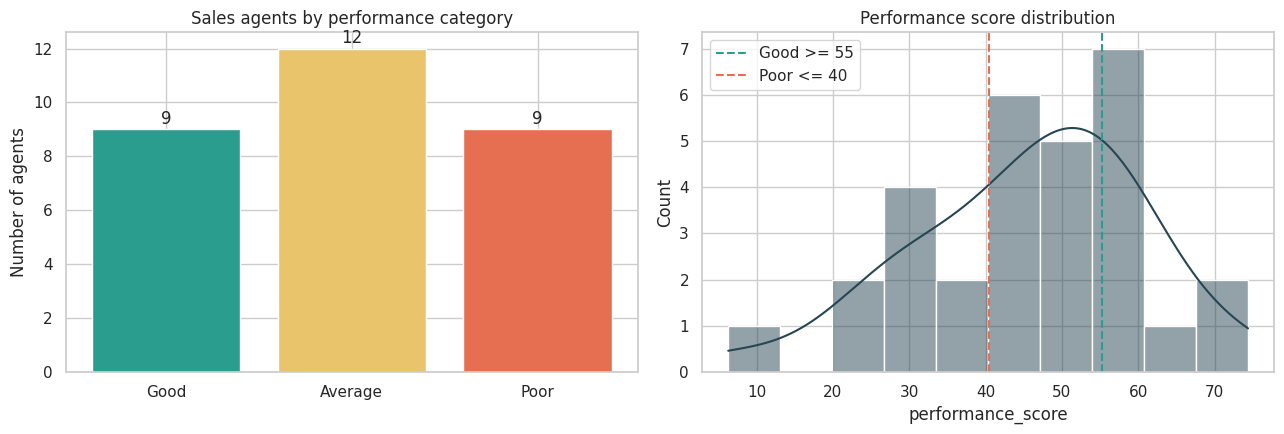

In [12]:
palette = {"Good": "#2a9d8f", "Average": "#e9c46a", "Poor": "#e76f51"}
hi, lo = agents["performance_score"].quantile([0.70, 0.30])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
counts = agents["category"].value_counts().reindex(ORDER)
ax[0].bar(counts.index, counts.values, color=[palette[c] for c in counts.index])
ax[0].set_title("Sales agents by performance category")
ax[0].set_ylabel("Number of agents")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 0.2, str(v), ha="center")

sns.histplot(agents["performance_score"], bins=10, kde=True, color="#264653", ax=ax[1])
ax[1].axvline(hi, color="#2a9d8f", ls="--", label=f"Good >= {hi:.0f}")
ax[1].axvline(lo, color="#e76f51", ls="--", label=f"Poor <= {lo:.0f}")
ax[1].set_title("Performance score distribution")
ax[1].legend()
plt.tight_layout()
plt.savefig(IMG / "01_category_distribution.png", dpi=150)
plt.show()

### 8.2 Top and bottom agents

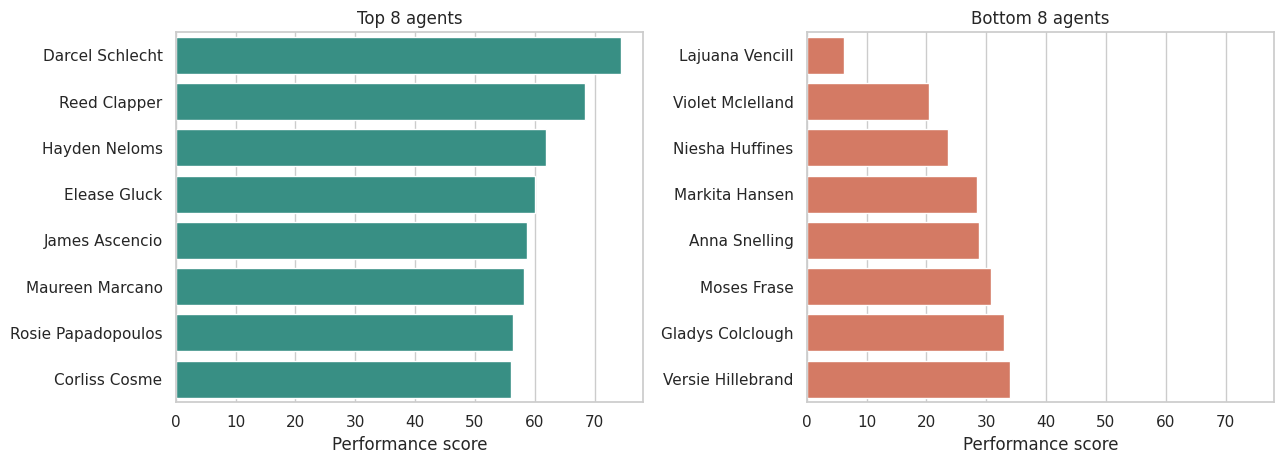

In [13]:
top = agents.nlargest(8, "performance_score")
bottom = agents.nsmallest(8, "performance_score")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
sns.barplot(data=top, y="sales_agent", x="performance_score", color="#2a9d8f", ax=ax[0])
ax[0].set_title("Top 8 agents")
sns.barplot(data=bottom, y="sales_agent", x="performance_score", color="#e76f51", ax=ax[1])
ax[1].set_title("Bottom 8 agents")
for a in ax:
    a.set_xlabel("Performance score"); a.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG / "02_top_bottom_agents.png", dpi=150)
plt.show()

### 8.3 Win rate vs. revenue per opportunity

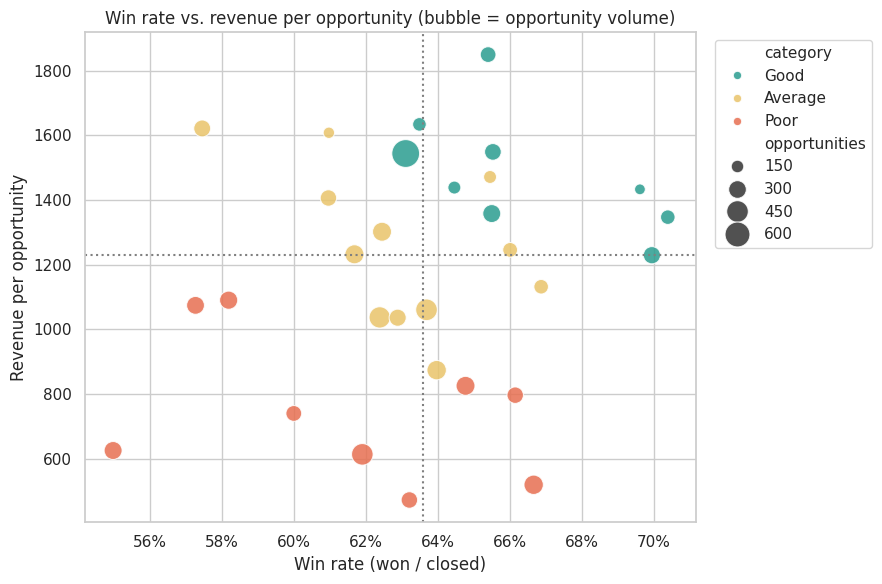

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=agents, x="win_rate", y="revenue_per_opp", hue="category", hue_order=ORDER,
                palette=palette, size="opportunities", sizes=(60, 400), alpha=0.85, ax=ax)
ax.axvline(agents["win_rate"].median(), color="grey", ls=":")
ax.axhline(agents["revenue_per_opp"].median(), color="grey", ls=":")
ax.set_title("Win rate vs. revenue per opportunity (bubble = opportunity volume)")
ax.set_xlabel("Win rate (won / closed)")
ax.set_ylabel("Revenue per opportunity")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(IMG / "03_winrate_vs_revenue.png", dpi=150)
plt.show()

### 8.4 Team view: regional offices and managers

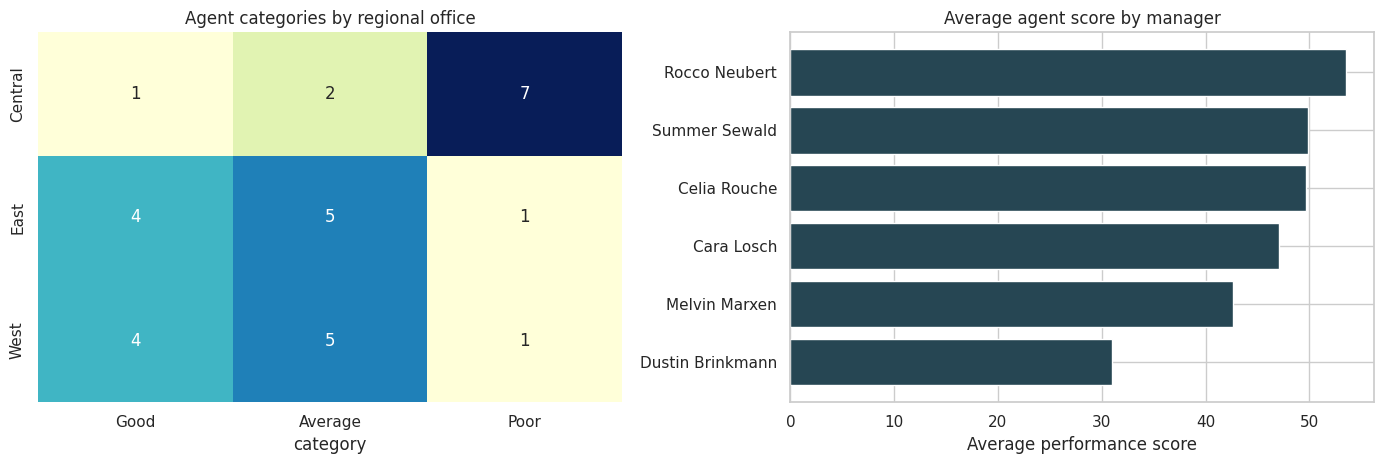

,agents,won,closed,revenue,avg_score,win_rate
manager,,,,,,
Rocco Neubert,5,691,1113,"1,960,545.00",53.54,0.62
Summer Sewald,5,828,1287,"1,964,750.00",49.83,0.64
Celia Rouche,5,610,962,"1,603,897.00",49.63,0.63
Cara Losch,5,480,745,"1,130,049.00",47.04,0.64
Melvin Marxen,5,882,1418,"2,251,930.00",42.64,0.62
Dustin Brinkmann,5,747,1186,"1,094,363.00",30.98,0.63


In [15]:
office_cat = pd.crosstab(agents["regional_office"], agents["category"])[ORDER]
mgr = agents.groupby("manager").agg(
    agents=("sales_agent", "count"), won=("won", "sum"), closed=("closed_deals", "sum"),
    revenue=("revenue", "sum"), avg_score=("performance_score", "mean"),
)
mgr["win_rate"] = mgr["won"] / mgr["closed"]
mgr = mgr.sort_values("avg_score")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(office_cat, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=ax[0])
ax[0].set_title("Agent categories by regional office")
ax[0].set_ylabel("")
ax[1].barh(mgr.index, mgr["avg_score"], color="#264653")
ax[1].set_title("Average agent score by manager")
ax[1].set_xlabel("Average performance score")
plt.tight_layout()
plt.savefig(IMG / "04_team_view.png", dpi=150)
plt.show()

mgr.sort_values("avg_score", ascending=False)

### 8.5 Product and sector performance (closed deals)

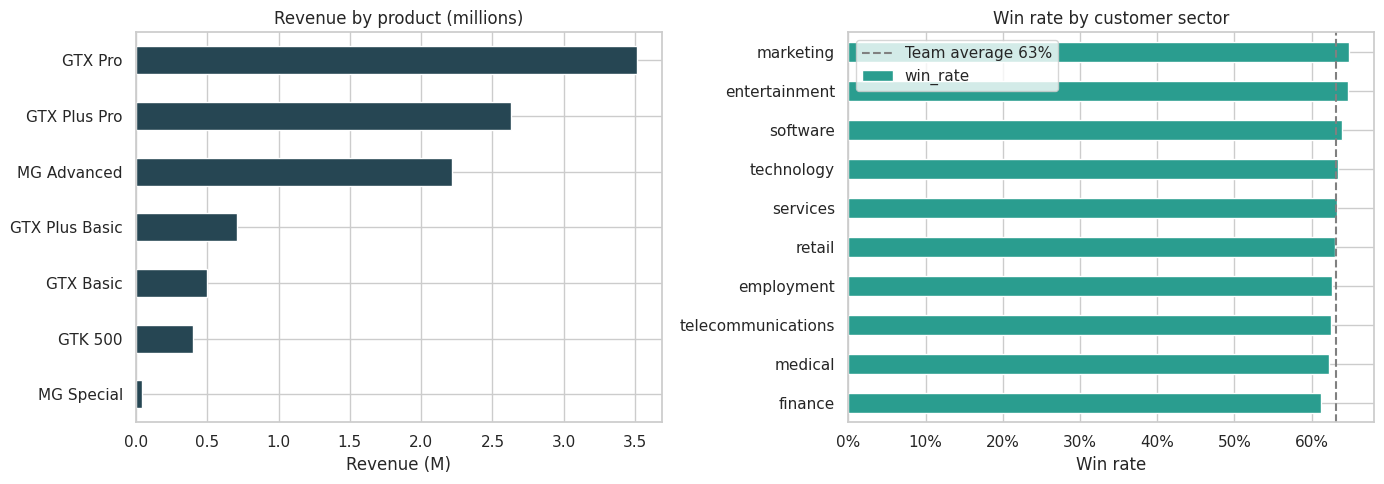

,closed,won,revenue,win_rate
product,,,,
GTX Pro,1147,729,"3,510,578.00",0.64
GTX Plus Pro,745,479,"2,629,651.00",0.64
MG Advanced,1084,654,"2,216,387.00",0.60
GTX Plus Basic,1051,653,"705,275.00",0.62
GTX Basic,1436,915,"499,263.00",0.64
GTK 500,25,15,"400,612.00",0.60
MG Special,1223,793,"43,768.00",0.65


In [16]:
closed = pipeline[pipeline["deal_stage"].isin(["Won", "Lost"])].merge(
    accounts[["account", "sector"]], on="account", how="left")

prod = closed.groupby("product").agg(
    closed=("opportunity_id", "count"),
    won=("deal_stage", lambda s: (s == "Won").sum()),
    revenue=("close_value", "sum"),
)
prod["win_rate"] = prod["won"] / prod["closed"]

sector = closed.groupby("sector").agg(
    closed=("opportunity_id", "count"),
    won=("deal_stage", lambda s: (s == "Won").sum()),
    revenue=("close_value", "sum"),
)
sector["win_rate"] = sector["won"] / sector["closed"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
prod.sort_values("revenue").assign(rev_m=lambda d: d["revenue"] / 1e6)["rev_m"].plot.barh(color="#264653", ax=ax[0])
ax[0].set_title("Revenue by product (millions)")
ax[0].set_xlabel("Revenue (M)"); ax[0].set_ylabel("")
sector["win_rate"].sort_values().plot.barh(color="#2a9d8f", ax=ax[1])
ax[1].axvline(p_all, color="grey", ls="--", label=f"Team average {p_all:.0%}")
ax[1].set_title("Win rate by customer sector")
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax[1].set_xlabel("Win rate"); ax[1].set_ylabel("")
ax[1].legend()
plt.tight_layout()
plt.savefig(IMG / "05_product_and_sector.png", dpi=150)
plt.show()

prod.sort_values("revenue", ascending=False)

### 8.6 Pipeline funnel and monthly revenue trend

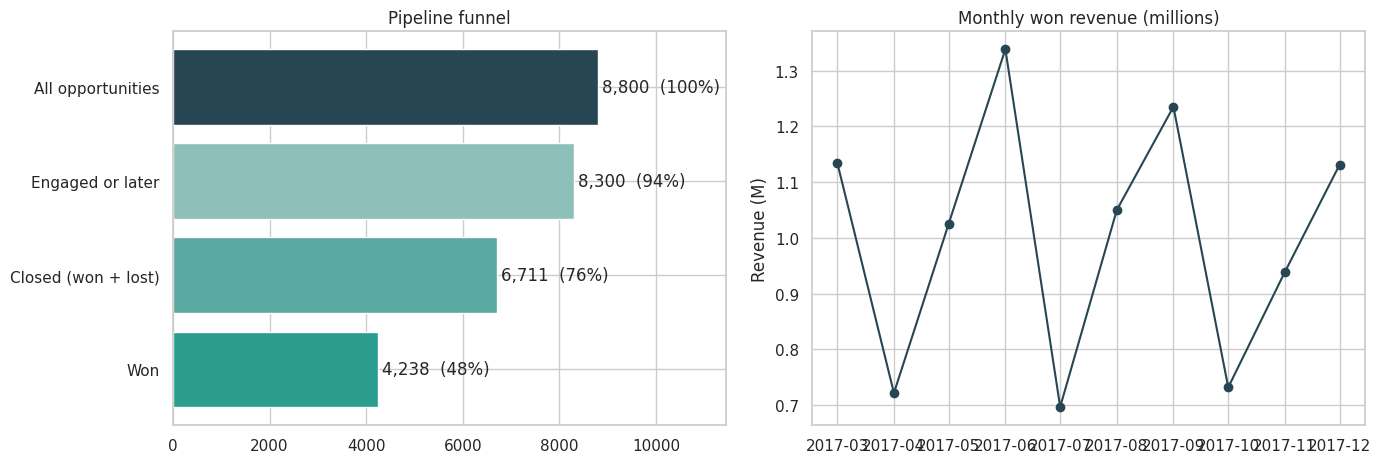

In [17]:
funnel = pd.Series({
    "All opportunities": len(pipeline),
    "Engaged or later": int(pipeline["engage_date"].notna().sum()),
    "Closed (won + lost)": len(closed),
    "Won": int((pipeline["deal_stage"] == "Won").sum()),
})
won = pipeline[pipeline["deal_stage"] == "Won"].copy()
monthly = won.groupby(won["close_date"].dt.to_period("M").dt.to_timestamp())["close_value"].sum() / 1e6

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(funnel.index[::-1], funnel.values[::-1], color=["#2a9d8f", "#5aa9a0", "#8fbfb9", "#264653"])
for i, v in enumerate(funnel.values[::-1]):
    ax[0].text(v + 80, i, f"{v:,}  ({v / funnel.iloc[0]:.0%})", va="center")
ax[0].set_xlim(0, funnel.iloc[0] * 1.3)
ax[0].set_title("Pipeline funnel")
ax[1].plot(monthly.index, monthly.values, marker="o", color="#264653")
ax[1].set_title("Monthly won revenue (millions)")
ax[1].set_ylabel("Revenue (M)"); ax[1].set_xlabel("")
plt.tight_layout()
plt.savefig(IMG / "06_funnel_and_trend.png", dpi=150)
plt.show()

## 9. How robust is the classification?

The weights are a judgment call. If the Good / Average / Poor labels flipped every time the weights changed, the ranking would not be trustworthy. Here the same agents are re-scored under four alternative weighting schemes.

In [18]:
schemes = {
    "Equal weights":         {"win_rate": 0.25, "revenue_per_opp": 0.25, "revenue": 0.25, "speed": 0.25},
    "Win-rate focused":      {"win_rate": 0.50, "revenue_per_opp": 0.20, "revenue": 0.20, "speed": 0.10},
    "Revenue focused":       {"win_rate": 0.15, "revenue_per_opp": 0.30, "revenue": 0.45, "speed": 0.10},
    "No cycle-time metric":  {"win_rate": 0.35, "revenue_per_opp": 0.35, "revenue": 0.30, "speed": 0.00},
}
base = agents["category"].astype(str)
rows = []
for name, w in schemes.items():
    alt = classify(score(w))
    rows.append({
        "scheme": name,
        "agents keeping same category": int((alt == base).sum()),
        "% unchanged": 100 * (alt == base).mean(),
        "Poor agents still Poor": int(((alt == "Poor") & (base == "Poor")).sum()),
    })
robust = pd.DataFrame(rows).set_index("scheme")
robust

,agents keeping same category,% unchanged,Poor agents still Poor
scheme,,,
Equal weights,28,93.33,9
Win-rate focused,24,80.00,7
Revenue focused,26,86.67,9
No cycle-time metric,28,93.33,9


In [19]:
always_poor = set(agents.loc[base == "Poor", "sales_agent"])
always_good = set(agents.loc[base == "Good", "sales_agent"])
for name, w in schemes.items():
    alt = classify(score(w))
    always_poor &= set(agents.loc[alt == "Poor", "sales_agent"])
    always_good &= set(agents.loc[alt == "Good", "sales_agent"])
print(f"Agents rated Poor under ALL five weightings: {len(always_poor)} -> {sorted(always_poor)}")
print(f"Agents rated Good under ALL five weightings: {len(always_good)} -> {sorted(always_good)}")
agents["robust_poor"] = agents["sales_agent"].isin(always_poor)
agents["robust_good"] = agents["sales_agent"].isin(always_good)

Agents rated Poor under ALL five weightings: 7 -> ['Anna Snelling', 'Gladys Colclough', 'Lajuana Vencill', 'Markita Hansen', 'Moses Frase', 'Niesha Huffines', 'Violet Mclelland']
Agents rated Good under ALL five weightings: 7 -> ['Corliss Cosme', 'Darcel Schlecht', 'Elease Gluck', 'Hayden Neloms', 'James Ascencio', 'Maureen Marcano', 'Reed Clapper']


## 10. Underperformers: what is driving them and what is it worth?

Section 7 showed that win rates are fairly similar across agents, so closing ability is probably not the main differentiator. Revenue per opportunity is, and it is almost entirely driven by deal size (correlation 0.92 in section 5). Deal size in turn depends on **which products** an agent sells. This section tests that and sizes both levers for each Poor agent:

- **Win-rate lever:** raise win rate to the team median on the deals already closed.
  `(median win rate - own win rate) x closed deals x median deal size`
- **Deal-size lever:** raise average deal size to the team median on the deals already won.
  `(median deal size - own deal size) x won deals`

Open pipeline is left out of both, which keeps the estimates conservative. The two levers overlap slightly, so their sum is an upper bound.

In [20]:
price = products.set_index("product")["sales_price"]
won_deals = pipeline[pipeline["deal_stage"] == "Won"].merge(
    agents[["sales_agent", "category"]], on="sales_agent")
won_deals["list_price"] = won_deals["product"].map(price)
won_deals["premium_product"] = won_deals["list_price"] >= 3000   # GTX Pro, GTX Plus Pro, MG Advanced, GTK 500

mix = won_deals.groupby("category", observed=True).agg(
    won_deals=("opportunity_id", "count"),
    premium_share=("premium_product", "mean"),
    avg_list_price=("list_price", "mean"),
    avg_close_value=("close_value", "mean"),
)
mix["premium_share"] = 100 * mix["premium_share"]
mix.rename(columns={"premium_share": "premium_product_share_%"})

,won_deals,premium_product_share_%,avg_list_price,avg_close_value
category,,,,
Good,1258,56.36,"2,973.44","2,961.55"
Average,1677,46.39,"2,481.49","2,478.00"
Poor,1303,29.93,"1,628.12","1,630.32"


In [21]:
median_wr = agents["win_rate"].median()
median_deal = agents["avg_deal_size"].median()
median_cycle = agents["avg_cycle_days"].median()

poor = agents[agents["category"] == "Poor"].copy()
poor["winrate_opportunity"] = (median_wr - poor["win_rate"]).clip(lower=0) * poor["closed_deals"] * median_deal
poor["dealsize_opportunity"] = (median_deal - poor["avg_deal_size"]).clip(lower=0) * poor["won"]
poor["revenue_opportunity"] = poor["winrate_opportunity"] + poor["dealsize_opportunity"]
poor = poor.sort_values("revenue_opportunity", ascending=False)

total = poor["revenue_opportunity"].sum()
print(f"Median win rate {median_wr:.1%} | median deal size {median_deal:,.0f} | median cycle {median_cycle:.0f} days")
print(f"Win-rate lever:  {poor['winrate_opportunity'].sum():>10,.0f}")
print(f"Deal-size lever: {poor['dealsize_opportunity'].sum():>10,.0f}")
print(f"Combined (upper bound): {total:,.0f} = {total / agents['revenue'].sum():.1%} of current revenue")
print(f"Top 3 agents hold {poor['revenue_opportunity'].head(3).sum() / total:.0%} of the opportunity")
poor[["sales_agent", "manager", "regional_office", "closed_deals", "win_rate", "avg_deal_size",
      "avg_cycle_days", "performance_score", "winrate_opportunity", "dealsize_opportunity"]].head(10)

Median win rate 63.6% | median deal size 2,552 | median cycle 52 days
Win-rate lever:     151,707
Deal-size lever:  1,201,894
Combined (upper bound): 1,353,600 = 13.5% of current revenue
Top 3 agents hold 53% of the opportunity


,sales_agent,manager,regional_office,closed_deals,win_rate,avg_deal_size,avg_cycle_days,performance_score,winrate_opportunity,dealsize_opportunity
17,Anna Snelling,Dustin Brinkmann,Central,336,0.62,"1,322.38",51.99,28.74,"14,452.96","255,722.73"
26,Versie Hillebrand,Dustin Brinkmann,Central,264,0.67,"1,066.44",51.82,33.95,0.00,"261,427.46"
29,Violet Mclelland,Cara Losch,East,193,0.63,"1,011.73",58.05,20.47,"1,861.54","187,891.14"
25,Lajuana Vencill,Dustin Brinkmann,Central,231,0.55,"1,532.54",62.87,6.28,"50,765.55","129,449.24"
16,Jonathan Berthelot,Melvin Marxen,Central,264,0.65,"1,666.00",51.33,39.62,0.00,"151,475.36"
23,Moses Frase,Dustin Brinkmann,Central,195,0.66,"1,606.06",64.69,30.84,0.00,"122,002.88"
27,Niesha Huffines,Melvin Marxen,Central,175,0.60,"1,685.34",54.59,23.67,"16,033.65","90,980.18"
12,Markita Hansen,Celia Rouche,West,227,0.57,"2,529.17",55.93,28.42,"36,619.23","2,944.70"
11,Gladys Colclough,Melvin Marxen,Central,232,0.58,"2,560.55",52.97,32.95,"31,973.69",0.00


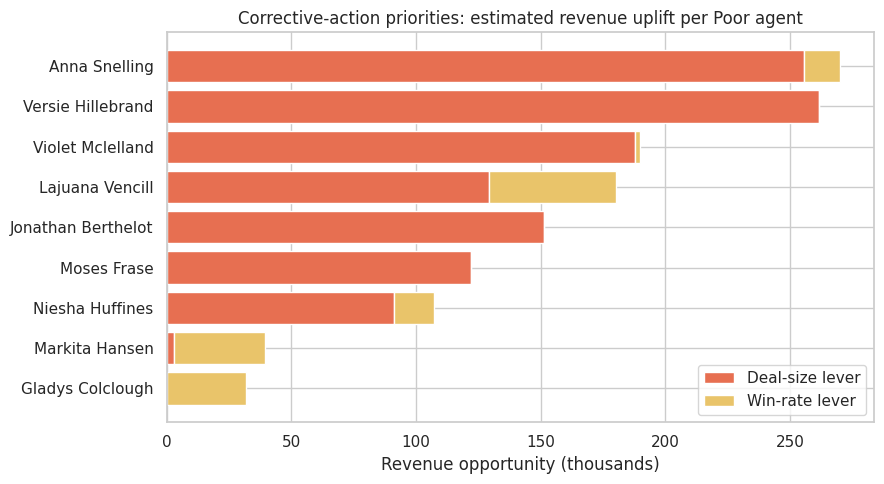

In [22]:
top_opp = poor.head(9).sort_values("revenue_opportunity")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_opp["sales_agent"], top_opp["dealsize_opportunity"] / 1e3, color="#e76f51", label="Deal-size lever")
ax.barh(top_opp["sales_agent"], top_opp["winrate_opportunity"] / 1e3, left=top_opp["dealsize_opportunity"] / 1e3,
        color="#e9c46a", label="Win-rate lever")
ax.set_title("Corrective-action priorities: estimated revenue uplift per Poor agent")
ax.set_xlabel("Revenue opportunity (thousands)")
ax.legend()
plt.tight_layout()
plt.savefig(IMG / "07_improvement_opportunity.png", dpi=150)
plt.show()

### Diagnosing the main weakness of each Poor agent

Each Poor agent is compared with the team median on three drivers, and the weakest one, relative to the median, is flagged as the main issue.

In [23]:
ratios = pd.DataFrame({
    "Low win rate":     poor["win_rate"] / median_wr,
    "Small deal size":  poor["avg_deal_size"] / median_deal,
    "Slow sales cycle": median_cycle / poor["avg_cycle_days"],
})
poor["main_issue"] = ratios.idxmin(axis=1)
poor["main_issue"].value_counts().to_frame("poor agents")

,poor agents
main_issue,
Small deal size,7
Low win rate,2


## 11. Export results

In [24]:
cols = ["sales_agent", "manager", "regional_office", "opportunities", "won", "lost", "open_deals",
        "revenue", "win_rate", "conversion_rate", "revenue_per_opp", "avg_deal_size",
        "avg_cycle_days", "performance_score", "category", "robust_poor", "robust_good"]
agents[cols].sort_values("performance_score", ascending=False).to_csv(OUT / "agent_scorecard.csv", index=False)
poor[["sales_agent", "manager", "regional_office", "closed_deals", "win_rate", "avg_deal_size",
      "avg_cycle_days", "performance_score", "revenue_opportunity", "main_issue", "robust_poor"]] \
    .to_csv(OUT / "poor_agent_action_list.csv", index=False)
print("Saved agent_scorecard.csv and poor_agent_action_list.csv to /outputs")

Saved agent_scorecard.csv and poor_agent_action_list.csv to /outputs


## 12. Key findings and recommendations

Results from the data above (30 active agents, 8,800 opportunities, about 10.0M in won revenue):

1. **The pipeline converts well overall.** 48% of opportunities were won, 28% lost and 24% are still open. On decided deals the team wins 63% of the time. Product win rates are all between 60% and 65%, so no product has a closing problem.
2. **Closing skill barely separates agents.** Agent win rates only span 55% to 70%, and just 2 of 30 differ from the team average by more than chance (Lajuana Vencill below, Maureen Marcano above). Ranking agents on win rate alone would mostly rank luck.
3. **Deal size is what separates Good from Poor.** Good agents earn about 1,487 per opportunity against 751 for Poor agents, and revenue per opportunity tracks deal size almost perfectly (correlation 0.92). Only 30% of Poor agents' wins are premium products (list price 3,000 or more), against 56% for Good agents.
4. **Poor performance is concentrated in the Central region.** Central holds 7 of the 9 Poor agents, and Dustin Brinkmann's team has 4 Poor agents out of 5 and the lowest team score. East and West have one Poor agent each.
5. **The ranking is reasonably stable.** Under four alternative weightings, 80% to 93% of agents keep their category, and 7 agents are Poor under all five schemes (Anna Snelling, Gladys Colclough, Lajuana Vencill, Markita Hansen, Moses Frase, Niesha Huffines, Violet Mclelland). Those are the safest to act on.
6. **The opportunity is in deal size, not win rate.** Lifting Poor agents' win rate to the median is worth only about 0.15M, whereas lifting their average deal size to the median is worth about 1.2M. The combined upper bound is about 1.35M, or 13.5% of current revenue, and three agents (Anna Snelling, Versie Hillebrand, Violet Mclelland) hold over half of it.

**Recommendations**
- Start with Central-region coaching on premium-product selling (GTX Pro, GTX Plus Pro, MG Advanced), not general closing-skills training.
- Before treating low deal size as a skill problem, check which accounts these agents are assigned. If Central territories mostly contain small customers, the gap is a territory-design issue and the fix is lead routing.
- Offer targeted closing and cycle-time support to Lajuana Vencill, the one agent who is statistically weak on win rate and also slow (about 63 days per won deal against a 52-day median).
- Use the seven agents who are Good under every weighting as peer mentors.

**Limitations**
- The data covers deals closed between March and December 2017 for a fictitious company, with only 30 agents, so every estimate carries real uncertainty.
- The score weights are judgment calls, and the Good / Poor cut-offs are percentile-based, so there will always be a bottom 30% even if everyone is performing well.
- The revenue component of the score favours high-volume agents (Darcel Schlecht handled 747 opportunities and produced 11.5% of all revenue).
- The opportunity sizing assumes an agent can move to the median deal size, which depends on customer demand and not only on the agent.